<a href="https://colab.research.google.com/github/SalmaAnindhia/PCVK26_25_Salma/blob/main/P9_Tugas_25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [2]:
BASE =  '/content/drive/MyDrive/MATKUL BU HANI/KTM/'

plat nomor.png


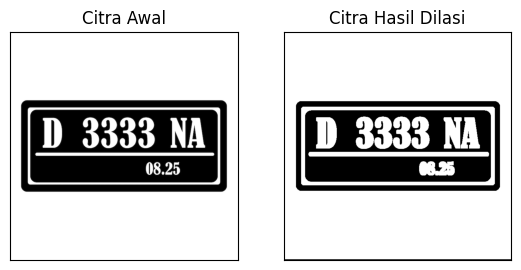

noisy_text.png


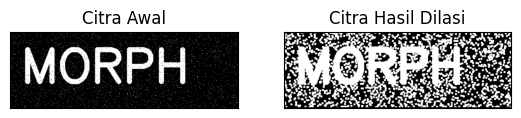

In [14]:
daftar_gambar = ['plat nomor.png', 'noisy_text.png']

def dilasi_citra(F,w):
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)
    SED= np.ones((w,w), dtype=np.uint8)
    constant1= (w-1)//2
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

for nama in daftar_gambar:
    print(nama)
    img_d= cv2.imread(BASE + nama, 0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(10,4))
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

plat nomor.png
[[1 1 1]
 [1 1 1]
 [1 1 1]]


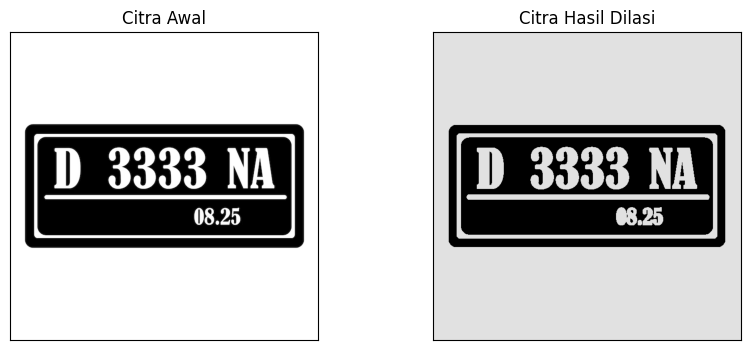

noisy_text.png
[[1 1 1]
 [1 1 1]
 [1 1 1]]


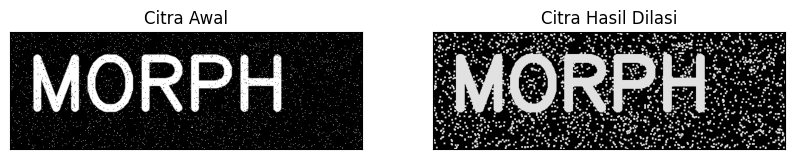

In [15]:
for nama in daftar_gambar:
    print(nama)
    img = cv2.imread(BASE + nama)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    dilasi = cv2.dilate(thresh,kernel,iterations = 1)
    print(kernel)

    plt.figure(figsize=(10,4))
    plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])
    plt.show()

plat nomor.png


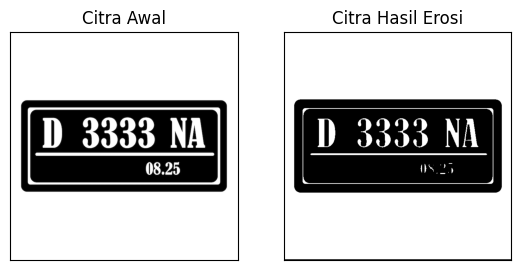

noisy_text.png


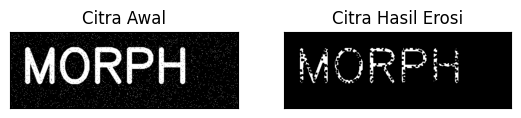

In [16]:
def erosi_citra(F,k):
    m,n= F.shape
    SE= np.ones((k,k), dtype=np.uint8)
    constant= (k-1)//2
    imgE= np.zeros((m,n), dtype=np.uint8)
    for i in range(constant, m-constant):
        for j in range(constant,n-constant):
            temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

for nama in daftar_gambar:
    print(nama)
    img_e= cv2.imread(BASE + nama, 0)
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    k=5
    imgE = erosi_citra(thresh1,k)

    plt.figure(figsize=(10,4))
    plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()

plat nomor.png


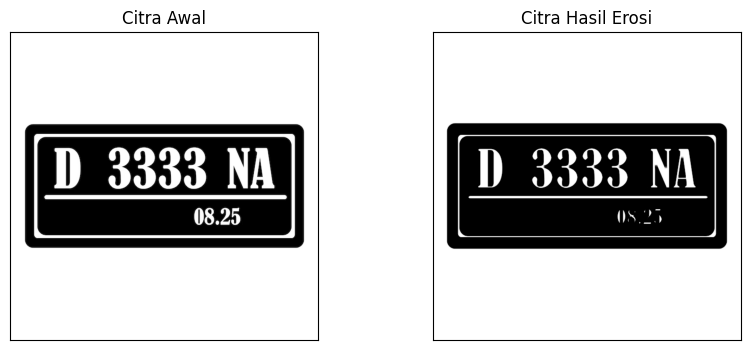

noisy_text.png


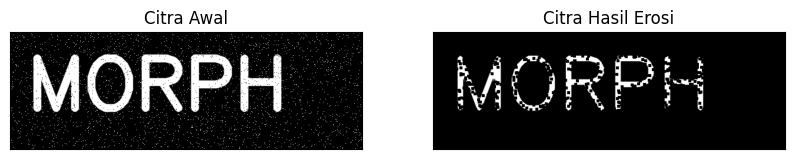

In [17]:
for nama in daftar_gambar:
    print(nama)
    img = cv2.imread(BASE + nama)
    kernel = np.ones((5,5),np.uint8)
    erosion = cv2.erode(img,kernel,iterations = 1)

    plt.figure(figsize=(10,4))
    plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])
    plt.show()

plat nomor.png - Opening tanpa library


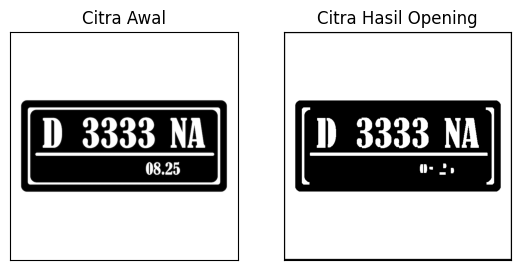

plat nomor.png - Opening dengan library


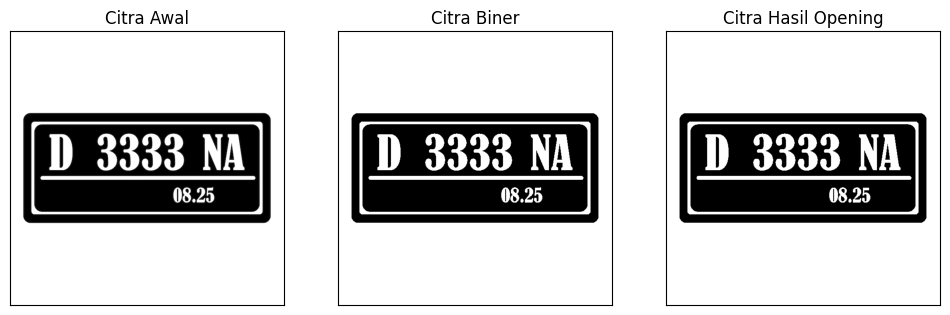

noisy_text.png - Opening tanpa library


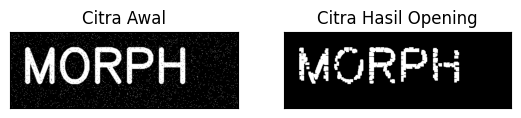

noisy_text.png - Opening dengan library


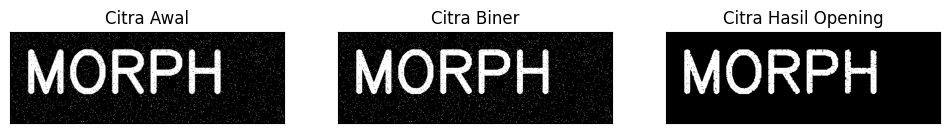

In [18]:
for nama in daftar_gambar:
    print(nama, '- Opening tanpa library')
    img_o= cv2.imread(BASE + nama, 0)
    reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgO = dilasi_citra(erosi_citra(thresho,k),k)

    plt.figure(figsize=(10,4))
    plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

    print(nama, '- Opening dengan library')
    img = cv2.imread(BASE + nama, 0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)

    plt.figure(figsize=(12,4))
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(openn,cmap = 'gray')
    plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
    plt.show()

plat nomor.png - Closing tanpa library


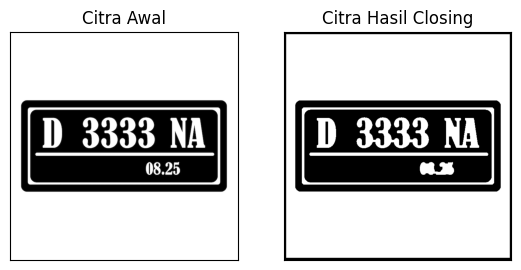

plat nomor.png - Closing dengan library


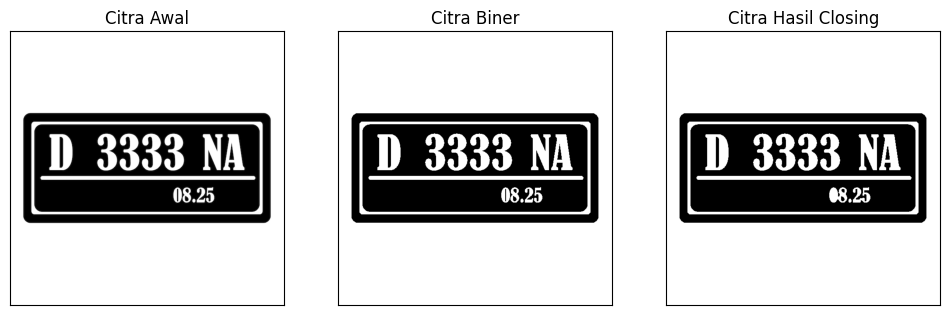

noisy_text.png - Closing tanpa library


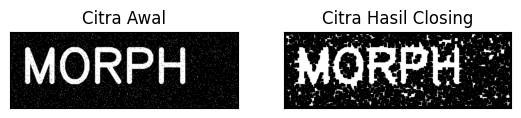

noisy_text.png - Closing dengan library


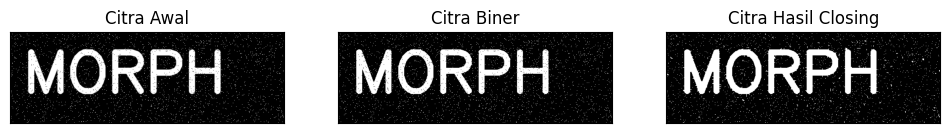

In [19]:
for nama in daftar_gambar:
    print(nama, '- Closing tanpa library')
    img_c= cv2.imread(BASE + nama, 0)
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    k=7
    imgC = erosi_citra(dilasi_citra(threshc,k),k)

    plt.figure(figsize=(10,4))
    plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

    print(nama, '- Closing dengan library')
    img = cv2.imread(BASE + nama, 0)
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3),np.uint8)
    closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)

    plt.figure(figsize=(12,4))
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133),plt.imshow(closs,cmap = 'gray')
    plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
    plt.show()

plat nomor.png - SED = Cross 3


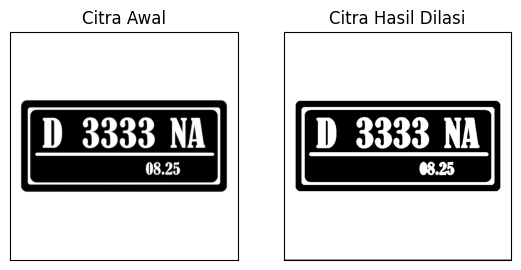

noisy_text.png - SED = Cross 3


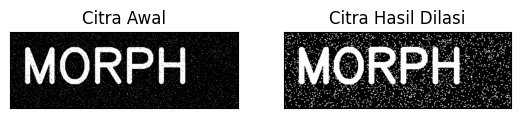

plat nomor.png - SED = Cross 5


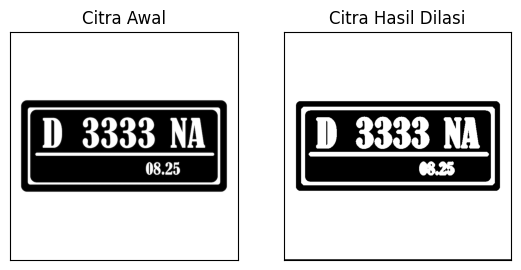

noisy_text.png - SED = Cross 5


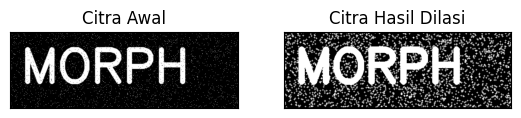

In [20]:
def dilasi_citra(F,w):
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype = np.uint8)
    constant1= (w-1)//2
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

for nama in daftar_gambar:
    print(nama, '- SED = Cross 3')
    img_d= cv2.imread(BASE + nama, 0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=3
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(10,4))
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

def dilasi_citra(F,w):
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype = np.uint8)
    constant1= (w-1)//2
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

for nama in daftar_gambar:
    print(nama, '- SED = Cross 5')
    img_d= cv2.imread(BASE + nama, 0)
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
    w=5
    imgD = dilasi_citra(thresh,w)

    plt.figure(figsize=(10,4))
    plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()

plat nomor.png - SED = Circle 3


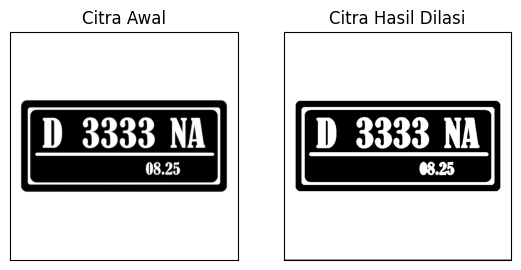

noisy_text.png - SED = Circle 3


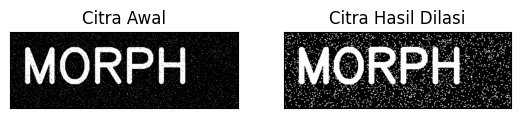

plat nomor.png - SED = Circle 5


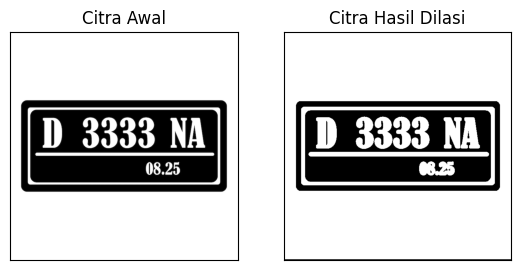

noisy_text.png - SED = Circle 5


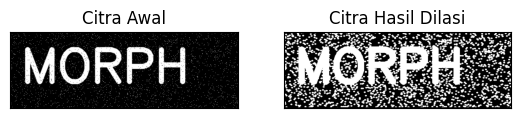

In [21]:
def dilasi_citra(F,w):
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)
    SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
    constant1= (w-1)//2
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

for w in [3, 5]:
    for nama in daftar_gambar:
        print(nama, '- SED = Circle', w)
        img_d= cv2.imread(BASE + nama, 0)
        ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
        imgD = dilasi_citra(thresh,w)

        plt.figure(figsize=(10,4))
        plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
        plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
        plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
        plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
        plt.show()

plat nomor.png - SE = Rectangle 3 x 5


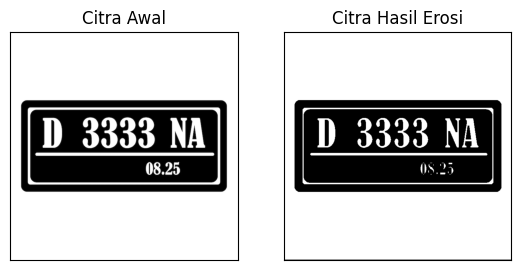

noisy_text.png - SE = Rectangle 3 x 5


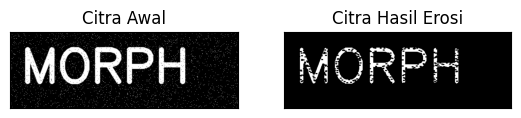

plat nomor.png - SE = Rectangle 5 x 7


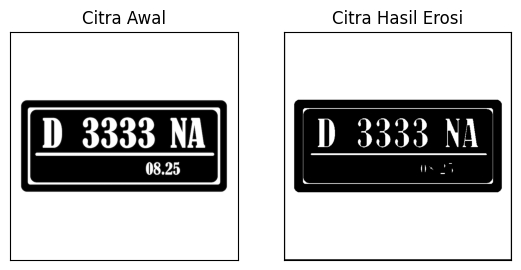

noisy_text.png - SE = Rectangle 5 x 7


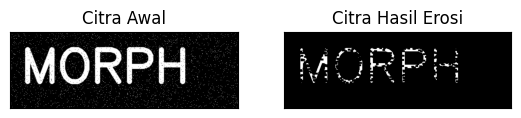

In [22]:
def erosi_citra(F,p,l):
    m,n= F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l))
    constant1= (l-1)//2
    constant2= (p-1)//2
    imgE= np.zeros((m,n), dtype=np.uint8)
    for i in range(constant1, m-constant1):
        for j in range(constant2,n-constant2):
            temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

for p, l in [(5, 3), (7, 5)]:
    for nama in daftar_gambar:
        print(nama, '- SE = Rectangle', l, 'x', p)
        img_e= cv2.imread(BASE + nama, 0)
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        imgE = erosi_citra(thresh1,p,l)

        plt.figure(figsize=(10,4))
        plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
        plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
        plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
        plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
        plt.show()

plat nomor.png - SE = Line Vertikal 3


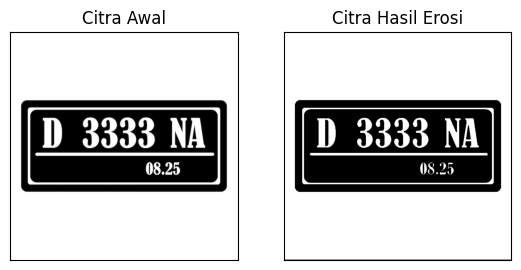

noisy_text.png - SE = Line Vertikal 3


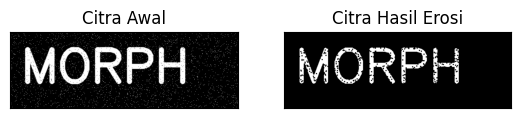

plat nomor.png - SE = Line Vertikal 5


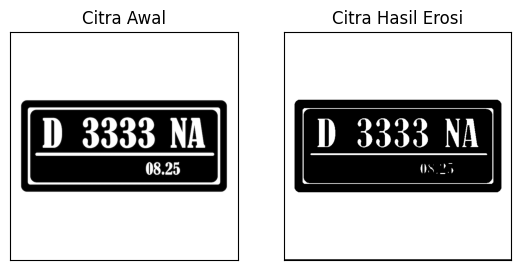

noisy_text.png - SE = Line Vertikal 5


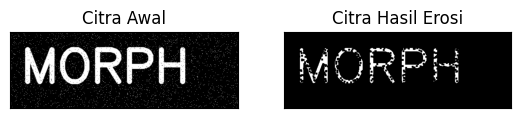

In [23]:
def erosi_citra(F,k):
    m,n= F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k))
    constant= (k-1)//2
    imgE= np.zeros((m,n), dtype=np.uint8)
    for i in range(constant, m-constant):
        for j in range(constant,n-constant):
            temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

for k in [3, 5]:
    for nama in daftar_gambar:
        print(nama, '- SE = Line Vertikal', k)
        img_e= cv2.imread(BASE + nama, 0)
        ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
        imgE = erosi_citra(thresh1,k)

        plt.figure(figsize=(10,4))
        plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
        plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
        plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
        plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
        plt.show()

plat nomor.png


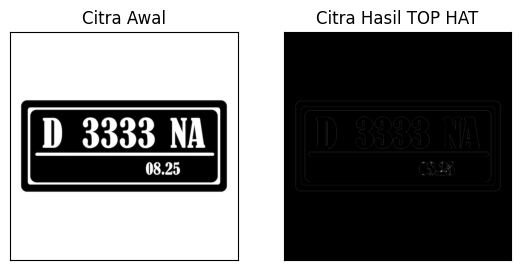

noisy_text.png


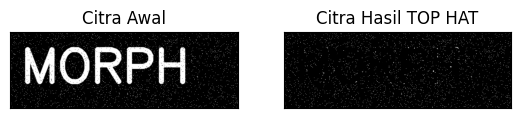

In [24]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

for nama in daftar_gambar:
    print(nama)
    img = cv2.imread(BASE + nama)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

    plt.figure(figsize=(10,4))
    plt.subplot(131),plt.imshow(img,cmap = 'gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
    plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
    plt.show()

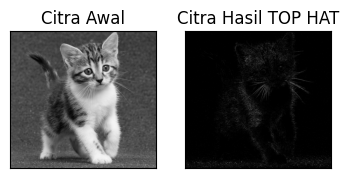

In [26]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                filterSize)

img = cv2.imread(BASE + 'kitten.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

input_image = img

tophat_img = cv2.morphologyEx(input_image,
              cv2.MORPH_TOPHAT,
              kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

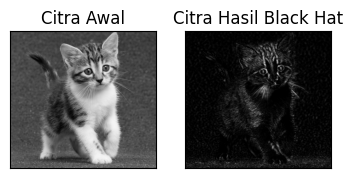

In [6]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread(BASE + 'kitten.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

In [16]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
from skimage import io
from skimage.util import img_as_float
from skimage import color
from skimage import morphology

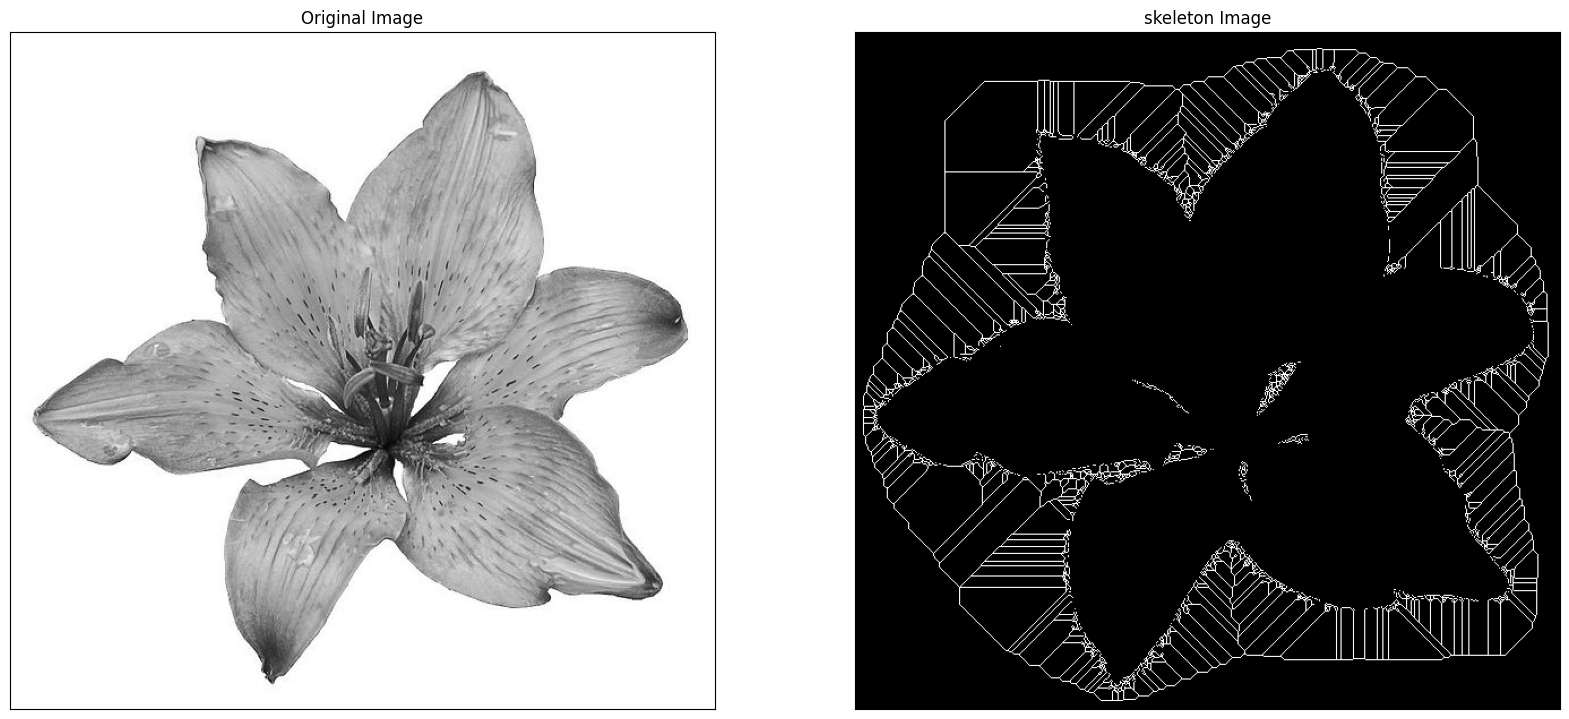

In [7]:
img = cv.imread(BASE + 'lily.jpg',0)
binary = img > filters.threshold_triangle(img)

binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(20,20))
plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

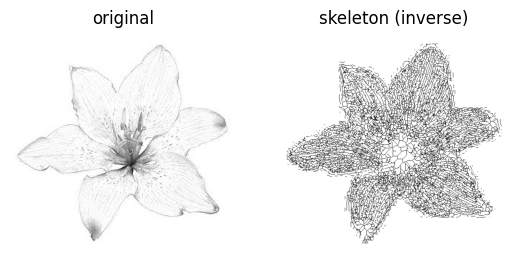

In [10]:
img = io.imread(BASE + 'lily.jpg')[..., 0]

binary = img < filters.threshold_triangle(img)

skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

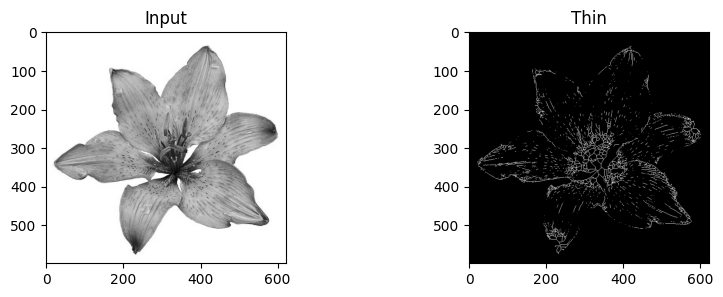

In [17]:
image = img_as_float(color.rgb2gray(io.imread(BASE + 'lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)
f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()